# 03 – Frozen Encoder
**Coursework Topic 6 – News Topic Classification (AG News)**

Freeze DistilBERT, chỉ train Classification Head.

```
Text → Tokenizer → DistilBERT (FROZEN) → Mean pooling → Head (TRAINED) → 4 lớp
```

In [1]:
import sys
sys.path.append("../src")   # để import models.py khi chạy notebook trong thư mục notebooks/
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import models
from models import LABELS

## 1. Cấu hình
`QUICK_TEST = True` để chạy thử nhanh (Thứ 4). Đổi thành `False` khi chạy chính thức (Thứ 5).

In [11]:
QUICK_TEST = True

if QUICK_TEST:
    cfg = dict(train_size=5000, val_size=1000, test_size=1000)
else:
    cfg = dict(train_size=None, val_size=None, test_size=None)  # toàn bộ AG News

print(cfg)

{'train_size': 5000, 'val_size': 1000, 'test_size': 1000}


## 2. Chạy thí nghiệm
Gồm: load dữ liệu → freeze encoder → trích đặc trưng → train head → đánh giá → lưu metrics, predictions, checkpoint.

In [3]:
out = models.run_experiment(max_len=64, batch_size=64, head_epochs=20, lr=1e-3, seed=42, **cfg)

Device: cpu | backbone: distilbert-base-uncased
train/val/test = 5000/1000/1000
Params: total=66,365,956 trainable=3,076 size=253.2 MB


train feats:   0%|          | 0/79 [00:00<?, ?it/s]

val feats:   0%|          | 0/16 [00:00<?, ?it/s]

test feats:   0%|          | 0/16 [00:00<?, ?it/s]

Test: acc=0.8870 macroF1=0.8867 | train 183.0s | infer 28.8s


## 3. Tham số và kích thước mô hình

In [12]:
row = out["row"]
print(f"Total params     : {row['total_params']:,}")
print(f"Trainable params : {row['trainable_params']:,}")
print(f"Model size       : {row['model_size_mb']:.1f} MB (checkpoint head: {row['checkpoint_size_mb']*1024:.1f} KB)")

Total params     : 66,365,956
Trainable params : 3,076
Model size       : 253.2 MB (checkpoint head: 13.8 KB)


## 4. Kết quả trên tập test

In [13]:
metrics = pd.read_csv("../results/metrics/frozen_encoder_metrics.csv")
metrics.T

,0
model,frozen_encoder
backbone,distilbert-base-uncased
accuracy,0.887
precision_macro,0.887604
recall_macro,0.887825
f1_macro,0.886692
train_time_s,182.971709
feature_extraction_time_s,180.01647
head_train_time_s,2.955239
inference_time_s,28.793309


In [6]:
print(classification_report(out["y_true"], out["y_pred"], target_names=LABELS, digits=4))

              precision    recall  f1-score   support

       World     0.9259    0.8459    0.8841       266
      Sports     0.9531    0.9919    0.9721       246
    Business     0.8608    0.8293    0.8447       246
    Sci/Tech     0.8106    0.8843    0.8458       242

    accuracy                         0.8870      1000
   macro avg     0.8876    0.8878    0.8867      1000
weighted avg     0.8887    0.8870    0.8868      1000



## 5. Learning curve của head

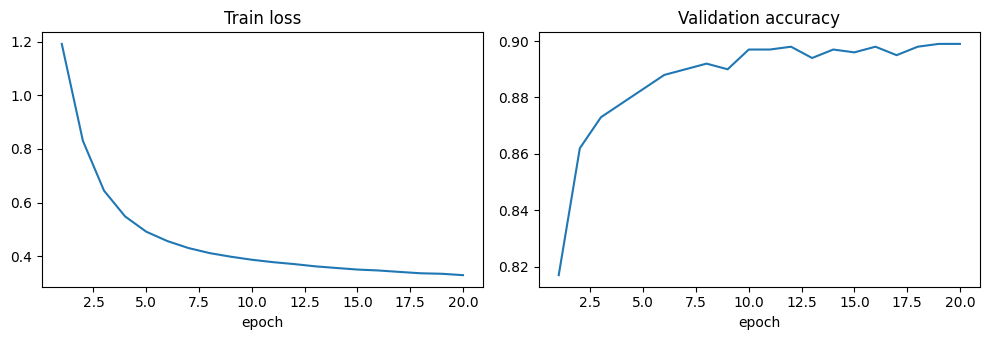

In [14]:
hist = pd.DataFrame(out["history"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["val_accuracy"]); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Confusion matrix (xem nhanh)
Bản chính thức để lưu vào `results/figures/` do `src/evaluate.py` (Trúc Chi) tạo.

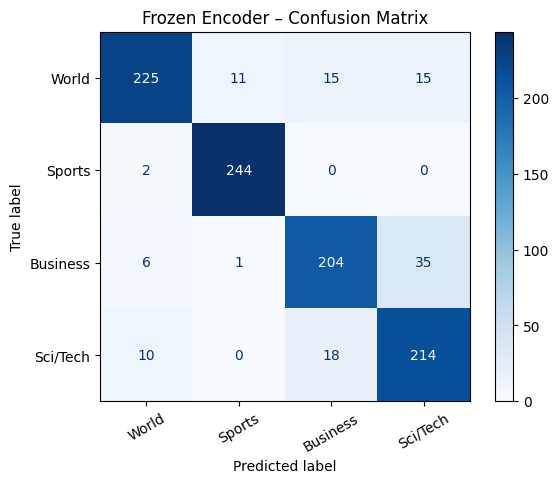

In [15]:
cm = confusion_matrix(out["y_true"], out["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues", xticks_rotation=30)
plt.title("Frozen Encoder – Confusion Matrix"); plt.show()

## 7. Một vài mẫu dự đoán sai

In [16]:
preds = pd.read_csv("../results/metrics/frozen_encoder_predictions.csv")
wrong = preds[~preds["correct"]].sort_values("confidence", ascending=False)
print(f"Sai {len(wrong)}/{len(preds)} mẫu")
wrong[["text", "true_name", "pred_name", "confidence"]].head(10)

Sai 113/1000 mẫu


,text,true_name,pred_name,confidence
62,Dodgers Nip Giants 3-2 in Crucial Series SAN F...,World,Sports,0.993839
734,US edge out Brazil for gold The United States ...,World,Sports,0.985511
423,"SBC links e-mail, voice messages, fax SBC on M...",Business,Sci/Tech,0.983395
652,Google #39;s New PC Search Tool Poses Risks NE...,Business,Sci/Tech,0.981505
36,"Ken Caminiti, 1996 NL MVP, Dies at Age 41 NEW ...",World,Sports,0.980134
104,Vodafone begins 3G service Vodafone launches i...,Business,Sci/Tech,0.979706
900,Lackluster Jobs Report Pushes Stocks Down NEW ...,World,Business,0.975874
624,Football: Brazil legend's UK debut Brazil foot...,World,Sports,0.974611
893,Stocks Climb on Drop in Consumer Prices NEW YO...,World,Business,0.973487
100,Mars water tops science honours The discovery ...,World,Sci/Tech,0.971385


## 8. Thử dự đoán một câu

In [17]:
samples = ["Manchester United won the match 3-1.",
           "Apple unveils a new chip for its laptops.",
           "Stocks fell as oil prices surged on Tuesday."]
names, confs = models.predict_texts(out["model"], out["tokenizer"], samples, max_len=64)
for s, n, c in zip(samples, names, confs):
    print(f"{n:9s} ({c:.2f})  {s}")

Sports    (0.99)  Manchester United won the match 3-1.
Sci/Tech  (0.96)  Apple unveils a new chip for its laptops.
Business  (0.92)  Stocks fell as oil prices surged on Tuesday.
